# Tópico 7 - Teorema da Amostragem e Nyquist

## Visão Geral e Objetivos
Neste notebook, investigamos empiricamente o **Teorema da Amostragem de Nyquist-Shannon**. Os objetivos principais são:
1. **Critério de Nyquist**: Demonstrar que a reconstituição perfeita de um sinal limitado em frequência exige que a frequência de amostragem atenda a $f_s > 2 f_{max}$.
2. **Condições de Amostragem**: Analisar um sinal senoidal contínuo $x(t) = \cos(2\pi f_0 t)$ de frequência $f_0 = 100\text{ Hz}$ sob três regimes distintos de amostragem:
   - **Superamostrado / Adequado ($f_s > 2 f_0$)**: $f_s = 500\text{ Hz}$
   - **Amostragem Crítica ($f_s \approx 2 f_0$)**: $f_s = 210\text{ Hz}$
   - **Subamostrado ($f_s < 2 f_0$)**: $f_s = 130\text{ Hz}$
3. **Análise Comparativa**: Visualizar as sequências discretas resultantes no domínio do tempo e avaliar seus espectros de magnitude via FFT.
4. **Exportação de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulações.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Definição do Sinal Contínuo Simulado e Amostragem Temporal

Definimos uma frequência analógica base $f_0 = 100\text{ Hz}$ e construímos a representação "contínua" simulada utilizando uma alta taxa de amostragem de referência ($f_{ref} = 10000\text{ Hz}$).

Abaixo, realizamos a amostragem desse sinal sob três condições de taxa de amostragem $f_s$:
- **Caso 1**: $f_{s1} = 500\text{ Hz}$ ($f_{s1} / f_0 = 5,0 > 2$)
- **Caso 2**: $f_{s2} = 210\text{ Hz}$ ($f_{s2} / f_0 = 2,1 \approx 2$)
- **Caso 3**: $f_{s3} = 130\text{ Hz}$ ($f_{s3} / f_0 = 1,3 < 2$)

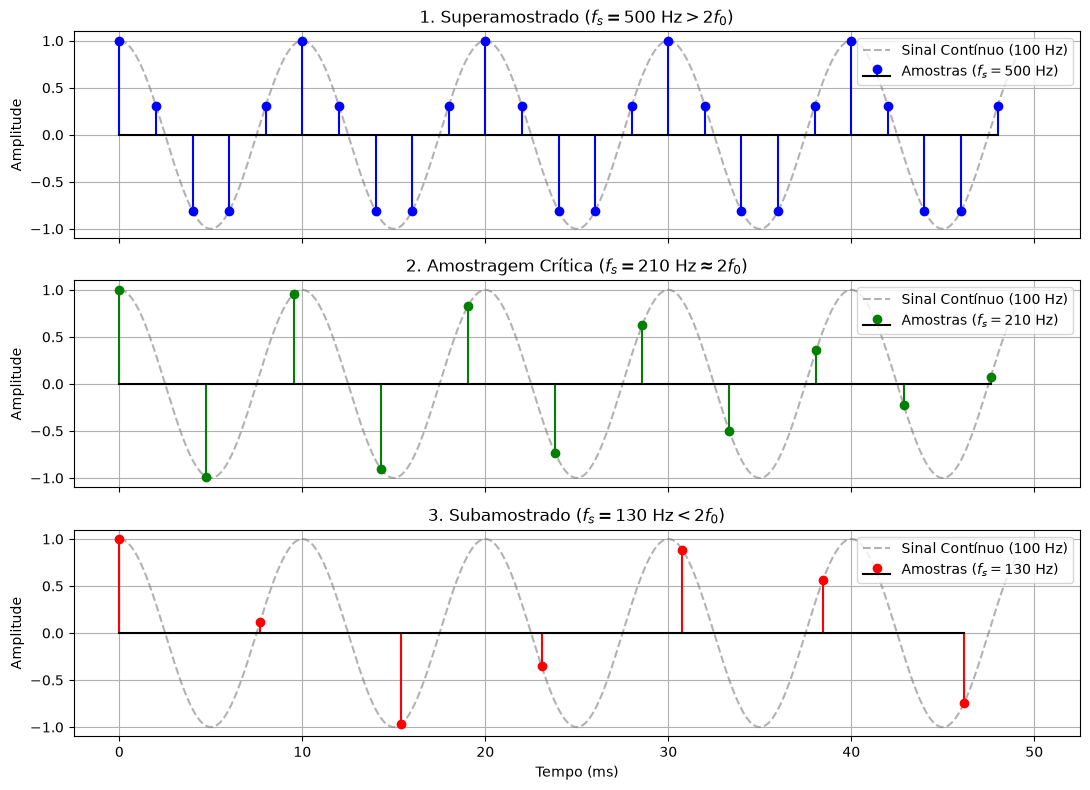

In [2]:
# Frequência analógica do sinal original
f0 = 100.0  # Hz

# Referência contínua (duração de 50 ms)
t_continua = np.linspace(0, 0.05, 5000)
x_continua = np.cos(2 * np.pi * f0 * t_continua)

# Três condições de amostragem
taxas_fs = [500.0, 210.0, 130.0]
titulos_casos = [
    r'1. Superamostrado ($f_s = 500\text{ Hz} > 2f_0$)',
    r'2. Amostragem Crítica ($f_s = 210\text{ Hz} \approx 2f_0$)',
    r'3. Subamostrado ($f_s = 130\text{ Hz} < 2f_0$)'
]
cores = ['b', 'g', 'r']

fig1, axs1 = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

for idx, fs in enumerate(taxas_fs):
    # Vetor de tempo discreto para o caso
    t_amostras = np.arange(0, 0.05, 1 / fs)
    x_amostras = np.cos(2 * np.pi * f0 * t_amostras)
    
    # Plot do sinal contínuo de fundo
    axs1[idx].plot(t_continua * 1000, x_continua, color='gray', linestyle='--', alpha=0.6, label='Sinal Contínuo (100 Hz)')
    # Plot das amostras discretas obtidas
    axs1[idx].stem(t_amostras * 1000, x_amostras, linefmt=f'{cores[idx]}-', markerfmt=f'{cores[idx]}o', basefmt='k-', label=f'Amostras ($f_s={fs:.0f}\\text{{ Hz}}$)')
    
    axs1[idx].set_title(titulos_casos[idx])
    axs1[idx].set_ylabel('Amplitude')
    axs1[idx].grid(True)
    axs1[idx].legend(loc='upper right')

axs1[-1].set_xlabel('Tempo (ms)')
plt.tight_layout()

# Salvamento da figura temporal
fig1.savefig("grafico_amostragem_tempo_nyquist.png")
plt.show()

## 2. Análise Espectral (FFT) sob Diferentes Condições de Amostragem

Para cada um dos três sinais discretos gerados, calculamos a FFT para identificar onde os picos de magnitude se localizam no domínio da frequência física em Hertz.

- **Para $f_{s1} = 500\text{ Hz}$**: O limite de Nyquist é $f_N = 250\text{ Hz}$. O pico surge corretamente em $100\text{ Hz}$.
- **Para $f_{s2} = 210\text{ Hz}$**: O limite de Nyquist é $f_N = 105\text{ Hz}$. O pico de $100\text{ Hz}$ permanece dentro da faixa sem sofrer aliasing.
- **Para $f_{s3} = 130\text{ Hz}$**: O limite de Nyquist é $f_N = 65\text{ Hz}$. Como $f_0 = 100\text{ Hz} > f_N$, o pico sofre rebatimento espectral (*aliasing*) para a frequência aparente $|100 - 130| = 30\text{ Hz}$.

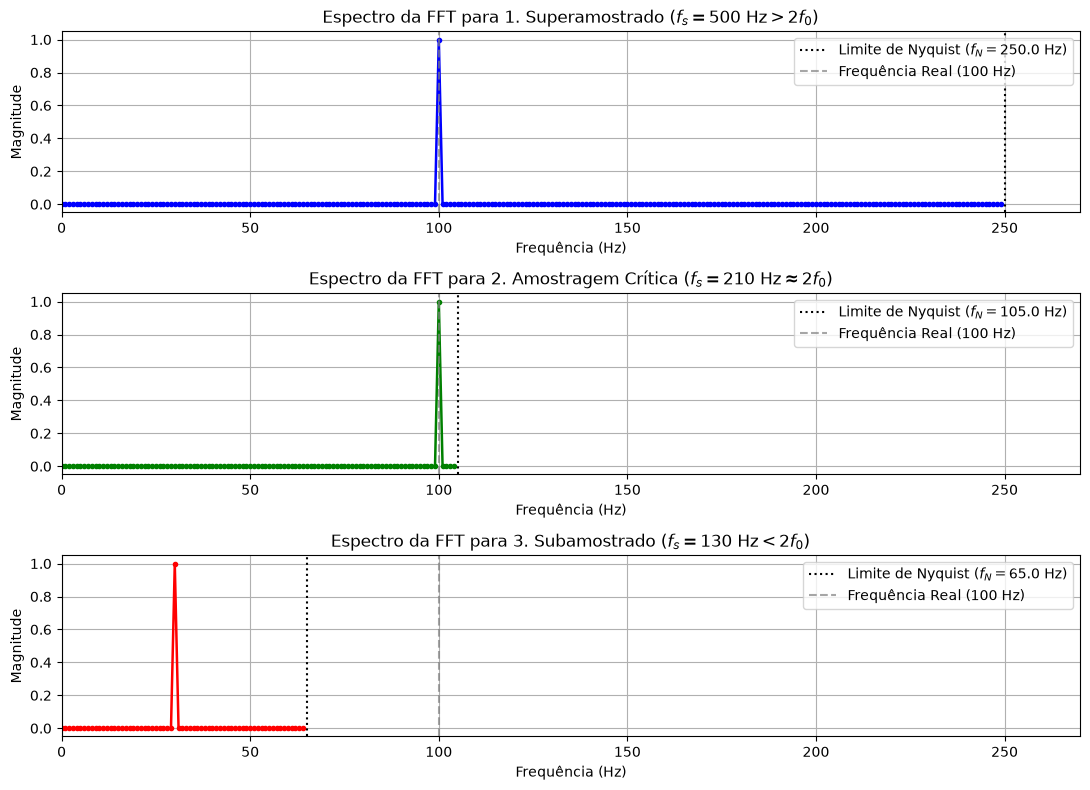

In [3]:
fig2, axs2 = plt.subplots(3, 1, figsize=(11, 8))

# Fixamos um tempo de observação padronizado de T_obs = 1.0 segundo para alta resolução espectral
T_obs = 1.0

for idx, fs in enumerate(taxas_fs):
    N_pontos = int(T_obs * fs)
    t_amostras = np.arange(N_pontos) / fs
    x_amostras = np.cos(2 * np.pi * f0 * t_amostras)
    
    # Cálculo da FFT
    X_fft = np.fft.fft(x_amostras)
    freqs = np.fft.fftfreq(N_pontos, d=1/fs)
    
    # Metade positiva do espectro
    metade = N_pontos // 2
    freqs_pos = freqs[:metade]
    magnitude = (2.0 / N_pontos) * np.abs(X_fft[:metade])
    
    f_nyquist = fs / 2.0
    
    axs2[idx].plot(freqs_pos, magnitude, color=cores[idx], linewidth=1.8, marker='o', markersize=3)
    axs2[idx].axvline(x=f_nyquist, color='black', linestyle=':', label=f'Limite de Nyquist ($f_N = {f_nyquist:.1f}\\text{{ Hz}}$)')
    axs2[idx].axvline(x=100.0, color='gray', linestyle='--', alpha=0.7, label='Frequência Real (100 Hz)')
    
    axs2[idx].set_title(f'Espectro da FFT para {titulos_casos[idx]}')
    axs2[idx].set_xlabel('Frequência (Hz)')
    axs2[idx].set_ylabel('Magnitude')
    axs2[idx].set_xlim(0, max(taxas_fs)/2 + 20)
    axs2[idx].grid(True)
    axs2[idx].legend(loc='upper right')

plt.tight_layout()

# Salvamento do gráfico de espectro
fig2.savefig("grafico_espectro_nyquist.png")
plt.show()

## 3. Conclusões sobre a Amostragem de Nyquist
- **Condição de Reconstrução**: Sempre que $f_s > 2 f_0$, a representação discreta preserva inteiramente as propriedades do sinal original, e o espectro registra o pico exatamente na frequência real ($100\text{ Hz}$).
- **Limite Crítico**: Na amostragem próxima de Nyquist ($f_s \approx 2 f_0$), o sinal ainda é recuperável, mas a densidade de amostras por ciclo é extremamente baixa ($N_{ciclo} \approx 2.1$).
- **Violação e Falseamento Espectral**: Quando $f_s < 2 f_0$, o sinal é subamostrado. A componente de $100\text{ Hz}$ ultrapassa a frequência de Nyquist ($65\text{ Hz}$) e é rebatida para $30\text{ Hz}$, tornando impossível distinguir o sinal original de uma senoide real de $30\text{ Hz}$.